# Location extraction: data and validation audit

This notebook checks whether the source annotations support reliable location extraction, how validation should be formed, and what the text implies for a recurrent sequence model. Full corpus checks stream through the CSVs. Tokenization comparisons use a deterministic bounded sample. The local `output/` cache is excluded from Git; delete it to refresh after changing the input files.

Run from the repository root or this directory with the environment in `requirements.txt`. The first run scans approximately nine million source rows and takes several minutes.

The split checks are chronological: sections 3 and 7 record earlier allocations. Section 8 contains the conservative duplicate-group split used by the experiments; use its counts or the root README for the current split. Section 9 and the final coverage section describe the later tokenizer checks.


In [1]:
from pathlib import Path
import ast
import csv
import json
import sys
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent.parent
elif PROJECT.name == 'eda':
    PROJECT = PROJECT.parent
HERE = PROJECT / 'eda'
sys.path.insert(0, str(PROJECT))
from eda.core.analysis import OUTPUT, DATA, SEED, competition_f1, span_f1, published_normalize, write_audit, WORD
from eda.core.splits import build_manifest

AUDIT_FILE = OUTPUT / 'audit.json'
if not AUDIT_FILE.exists():
    write_audit()
audit = json.loads(AUDIT_FILE.read_text(encoding='utf-8'))
print(f'Seed: {audit["seed"]}; UK: {audit["uk"]["counts"]["rows"]:,} rows; RU: {audit["ru"]["counts"]["rows"]:,} rows; test: {audit["test"]["count"]} rows')

Seed: 3012026; UK: 1,010,000 rows; RU: 8,028,840 rows; test: 477 rows


## 1. Source inventory and annotation integrity

The supplied Ukrainian `is_valid` flag is an initial validation split. Russian `doc_id` is a grouping key. Test `locations` values are placeholders, so they provide no negative labels.

In [2]:
rows = []
for source in ('uk', 'ru'):
    c = audit[source]['counts']; total = c['rows']
    rows.append({'source': source, 'rows': total, 'location rows %': 100*c['loc_positive_rows']/total,
                 'no location %': 100*c['no_locations']/total, 'locations': c['loc_mentions'],
                 'empty text': c.get('empty_text', 0), 'invalid location offsets': c.get('loc_invalid_bounds', 0),
                 'location parse errors': c.get('loc_parse_error', 0),
                 'overlap with organization': c.get('loc_overlaps_org', 0)})
display(pd.DataFrame(rows).round(2))
print('Supplied UK validation rows:', audit['uk']['counts'].get('valid_1', 0))
print('Example annotation errors:', audit['uk']['errors'][:3] + audit['ru']['errors'][:3])

,source,rows,location rows %,no location %,locations,empty text,invalid location offsets,location parse errors,overlap with organization
0,uk,1010000,23.11,76.89,345114,0,0,0,564
1,ru,8028840,30.69,69.31,3708173,0,0,0,9


Supplied UK validation rows: 10000
Example annotation errors: []


The two corpora have different positive-row rates: 23.1% in Ukrainian and 30.7% in Russian. The full scan found no malformed or out-of-range spans. This establishes structural integrity, but it does not guarantee that every span has the intended semantic boundary.

In [3]:
examples = []
for source in ('uk', 'ru'):
    for row in audit[source]['sample']:
        if row['loc'] and len(examples) < (6 if source == 'uk' else 12):
            examples.append({'source': source, 'text': row['text'][:140].replace('\n', ' ↵ '),
                             'locations': [row['text'][a:b] for a,b in row['loc'][:4]]})
display(pd.DataFrame(examples))

,source,text,locations
0,uk,"А перед цим Оля (до речі, майстер спорту, №1 н...","[України, Тарвізіо]"
1,uk,"Якщо це станеться, нам буде важче повертати Крим.",[Крим]
2,uk,Про це повідомляє УНН з посиланням відділ кому...,[Одеській області]
3,uk,Тож Україна навіть у разі дефолту російських о...,[Україна]
4,uk,"За Південним Вузлом ми позбавляємося чогось, з...",[Південним Вузлом]
5,uk,В рамках 6-го туру чемпіонату Білорусі Динамо ...,[Білорусі]
6,ru,"Такая возможность особенно ценна, если учесть,...",[Луне]
7,ru,"Кроме того, Медведев предложил сократить колич...",[России]
8,ru,Лондонский магистратский суд возобновил в четв...,[Россию]
9,ru,"По сведениям алжирских журналистов, посредник ...",[Северной Африке]


In [4]:
with (DATA / 'labeling_sample.csv').open(newline='', encoding='utf-8') as handle:
    qualitative = list(csv.DictReader(handle))
alignment = []
for row in qualitative:
    spans = ast.literal_eval(row['loc_markers'])
    from_offsets = [row['text'][start:end] for start,end in spans]
    alignment.append(from_offsets == ast.literal_eval(row['locations']))
print(f'Qualitative sample: {len(qualitative)} rows; location strings match offset slices in {sum(alignment)} rows.')
display(pd.DataFrame([{'text': r['text'][:150].replace('\n',' ↵ '), 'locations': r['locations']}
                      for r in qualitative[:8]]))

Qualitative sample: 26 rows; location strings match offset slices in 26 rows.


,text,locations
0,-261.310,[]
1,"Проспект Бандери стоїть, як і пів міста… довго...",['Проспект Бандери']
2,☢️Радіаційний фон (мкР/год) по Київщині станом...,"['Київщині', 'Чорнобиль', 'Київ', 'Тетерів', '..."
3,"Друзі. Останні дві ночі, і ще декілька наступн...",['проспекті Івасюка']
4,Сьогодні з Києва до Хелма вперше вирушив новий...,"['Києва', 'Хелма']"
5,Подовження роботи закладів харчування ↵ ↵ Вла...,['Києву']
6,"Нарешті офіційні новини, які можна розповідати...",[]
7,ДТП біля заїзду в ТЦ Аркадія ↵ ↵ 📍Індустріаль...,['ТЦ Аркадія']


The labeled examples also raise a policy question: one post labels `Проспект Бандери` but leaves a footer mention of `Оболонь` unmarked. Another labels `ТЦ Аркадія` while leaving `Індустріальний міст` unmarked. These are examples to review, not proof of a consistent rule. The 26 rows are too few to tune a model or estimate error rates.

Offsets are interpreted as Python string slices `[start:end]`. The examples above make the convention inspectable; the audit counts out-of-range and empty spans across all rows. Category overlap is worth reviewing because a location inside an organization name may be labeled differently across sources.

## 2. The competition score

The [published evaluation rule](https://www.kaggle.com/competitions/kse-ua-location-extraction-2026/overview/evaluation) pools true positives, false positives, and false negatives over normalized *sets of location strings per text*. Repeated mentions of the same name in one text count once. The displayed punctuation expression is a literal regex string rather than an interpolated character class; these examples check its observed behavior.

In [5]:
cases = [
    ('case', [['Київ']], [['київ']]),
    ('repeated mention', [['Київ','Київ']], [['Київ']]),
    ('house number', [['вул. Хрещатик 1']], [['вул. Хрещатик 2']]),
    ('punctuation', [['Київ']], [['Київ!']]),
    ('partial name', [['Київська область']], [['Київська']]),
    ('all empty', [[]], [[]]),
]
display(pd.DataFrame([{'case': name, 'F1': competition_f1(actual, predicted)['f1'],
                       'truth normalized': [published_normalize(x) for x in actual[0]],
                       'prediction normalized': [published_normalize(x) for x in predicted[0]]}
                      for name, actual, predicted in cases]))

,case,F1,truth normalized,prediction normalized
0,case,1.0,[київ],[київ]
1,repeated mention,1.0,"[київ, київ]",[київ]
2,house number,1.0,[вул хрещатик],[вул хрещатик]
3,punctuation,0.0,[київ],[київ!]
4,partial name,0.0,[київська область],[київська]
5,all empty,1.0,[],[]


For model development, report this score with precision and recall. Exact character span F1 is a useful complementary diagnostic on the source corpora: it distinguishes boundaries and repeated mentions, though it is sensitive to annotation policy. Test texts have no public gold offsets.

In [6]:
print('One of two repeated mentions found:', span_f1([[(0,4),(10,14)]], [[(0,4)]]))
print('Wrong boundary:', span_f1([[(0,4)]], [[(0,5)]]))

One of two repeated mentions found: {'tp': 1, 'fp': 0, 'fn': 1, 'precision': 1.0, 'recall': 0.5, 'f1': 0.66666667}
Wrong boundary: {'tp': 0, 'fp': 1, 'fn': 1, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


## 3. Exact duplicates and validation leakage

The duplicate query groups by the exact text, verifies equality, and counts cross-source and cross-flag groups. Its result determines whether the supplied Ukrainian split needs adjustment before comparing models.

In [7]:
display(pd.DataFrame([audit['duplicates']]).fillna(0).astype(int))

,duplicate_texts,duplicate_rows,cross_source_texts,uk_cross_split_texts,conflicting_marker_texts,uk_valid_rows_in_duplicate_groups,hash_collisions_in_duplicate_groups
0,251830,777785,0,52,4786,52,0


Exact repetition is substantial: 777,785 rows belong to 251,830 duplicate-text groups. 52 texts cross the supplied Ukrainian validation flag, and 4,786 duplicate texts have conflicting location-marker strings. Manual examples include a Russian place marked in some copies and absent in others, and `Associated Press` marked as a location in one copy. **These groups are excluded from training and validation**.

The frozen split keeps the supplied UK validation rows, adds about 4% of remaining UK texts, and selects about 2% of Russian documents. The exact membership is determined by `split_rules.json` and materialized locally. Training rows whose text appears in validation, plus all conflicting duplicate groups, are excluded. The 26 supplied labeled examples remain a qualitative check.

In [8]:
SUMMARY_FILE = OUTPUT / 'split_summary.json'
if not SUMMARY_FILE.exists():
    build_manifest()
split = json.loads(SUMMARY_FILE.read_text(encoding='utf-8'))
display(pd.DataFrame(split['counts'], columns=split['columns']))
print('Train–validation exact text overlaps:', split['train_validation_text_overlap'])
print('Russian documents split across cohorts:', split['russian_document_split_violations'])

,source,split,rows,location_rows,annotation_conflict_rows
0,ru,exclude_conflict,22562,14971,22562
1,ru,exclude_duplicate,98608,12706,0
2,ru,ru_holdout,159685,48630,0
3,ru,train,7747985,2388129,0
4,uk,exclude_duplicate,48,6,0
5,uk,train,960035,221927,0
6,uk,uk_holdout,39917,9185,0
7,uk,uk_valid,10000,2303,0


Train–validation exact text overlaps: 0
Russian documents split across cohorts: 0


The resulting validation cohorts contain 10,000 supplied Ukrainian rows, 39,917 extra Ukrainian rows, and 159,685 Russian rows. The split excludes 22,562 Russian rows with conflicting duplicate annotations, plus 98,608 Russian and 48 Ukrainian training rows whose text also occurs in validation. Exact train–validation overlap is zero; retained Russian rows stay grouped by document. These are source-distribution checks; the domain notebook tests how far they are from competition text.

Neither source file supplies a reliable timestamp. Russian `doc_id` is used for grouping, not treated as chronology; a time split would need actual publication dates.

In [9]:
import duckdb
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sample_rows = pd.DataFrame([{'source': s, 'row_id': r['row_id'], 'text': r['text']}
                            for s in ('uk','ru') for r in audit[s]['sample']])
db = duckdb.connect()
db.register('sample_rows', sample_rows)
sample_split = db.execute('''SELECT s.source, s.row_id, s.text, m.split
                             FROM sample_rows s JOIN read_parquet(?) m
                             ON s.source=m.source AND s.row_id=m.row_id''',
                          [(OUTPUT/'split_manifest.parquet').as_posix()]).df()
db.close()
near_rows = []
for source in ('uk','ru'):
    part = sample_split[sample_split.source==source]
    train = part[part.split=='train'].reset_index(drop=True)
    valid = part[part.split.isin(('uk_valid','uk_holdout','ru_holdout'))].reset_index(drop=True)
    vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(3,5), min_df=2, max_features=100000)
    train_vectors = vectorizer.fit_transform(train.text)
    scores = cosine_similarity(vectorizer.transform(valid.text), train_vectors)
    best = scores.argmax(axis=1)
    maximum = scores[np.arange(len(valid)), best]
    near_rows.append({'source': source, 'sampled validation texts': len(valid),
                      'similarity > 0.8 %': 100*np.mean(maximum > 0.8),
                      'similarity > 0.9 %': 100*np.mean(maximum > 0.9)})
    if source=='uk':
        examples_near = pd.DataFrame({'similarity': maximum, 'validation': valid.text,
                                      'nearest training': train.text.iloc[best].to_numpy()})
display(pd.DataFrame(near_rows).round(2))
display(examples_near.nlargest(3,'similarity').assign(
    validation=lambda d: d.validation.str.slice(0,160),
    **{'nearest training': lambda d: d['nearest training'].str.slice(0,160)}))

,source,sampled validation texts,similarity > 0.8 %,similarity > 0.9 %
0,uk,182,0.00,0.0
1,ru,117,0.85,0.0


,similarity,validation,nearest training
44,0.622770,Про це йдеться у повідомленні на сайті Мінфіну...,Про це йдеться в повідомленні на сайті компанії.
107,0.512478,"Про це сьогодні, 16 червня, повідомляє відділ ...",Як повідомляє Відділ комунікації поліції Києва...
123,0.477082,За тобою правда - - Україна Молода Передплата ...,Закон про трансплантацію органів підтримали у ...


In this bounded character n-gram check, none of 182 sampled Ukrainian validation texts exceeds 0.8 similarity to a sampled training text; one of 117 Russian validation texts does. No pair exceeds 0.9. This does not rule out rare near duplicates in the full corpora. Revisit templates if local validation looks unexpectedly optimistic.

## 4. Text, entity, and domain profiles

These full-data text-length bins and bounded sample comparisons show where padding, truncation, and corpus mixing matter. The test has 477 texts; no inference about its location prevalence is possible from its placeholder labels.

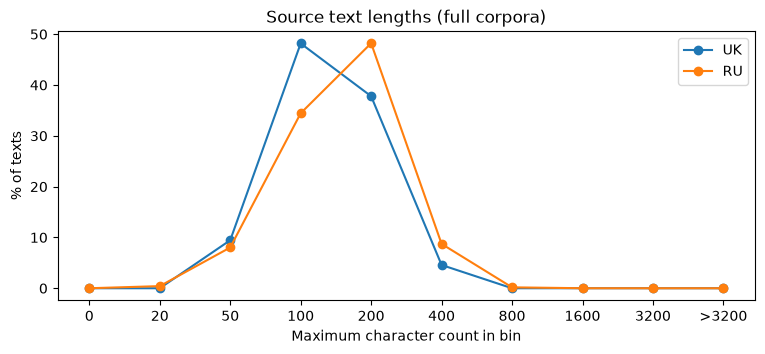

In [10]:
bins = ['0','20','50','100','200','400','800','1600','3200','>3200']
fig, ax = plt.subplots(figsize=(9, 3.5))
for source in ('uk','ru'):
    counts = audit[source]['text_length_bins']; total = audit[source]['counts']['rows']
    ax.plot(bins, [100*counts.get(b,0)/total for b in bins], marker='o', label=source.upper())
ax.set(ylabel='% of texts', xlabel='Maximum character count in bin', title='Source text lengths (full corpora)')
ax.legend(); plt.show()

In [11]:
features = ('characters','words','newlines','urls','emoji','uk_chars','ru_chars','digits')
profile = []
for source in ('uk','ru'):
    sample = audit[source]['sample']
    profile.append({'source': source, 'n': len(sample), **{f: np.mean([r[f] for r in sample]) for f in features}})
test = audit['test']['rows']
profile.append({'source': 'test', 'n': len(test), **{f: np.mean([r[f] for r in test]) for f in features}})
display(pd.DataFrame(profile).round(2))
display(pd.DataFrame([{'source': s, 'location length bin': b, 'mentions': n}
                      for s in ('uk','ru') for b,n in audit[s]['mention_length_bins'].items()])
        .pivot(index='location length bin', columns='source', values='mentions').fillna(0).astype(int))

,source,n,characters,words,newlines,urls,emoji,uk_chars,ru_chars,digits
0,uk,4000,101.84,17.98,0.00,0.00,0.0,6.20,0.00,0.78
1,ru,6000,119.35,20.02,0.00,0.00,0.0,0.00,2.00,1.35
2,test,477,395.41,69.56,5.17,0.04,0.6,21.64,0.31,5.31


source,ru,uk
location length bin,,
100,385,118
20,3622745,331657
200,4,0
50,85039,13339


Competition texts are much longer: 395 characters on average versus 102 Ukrainian and 119 Russian in the samples. The source CSVs contain no newlines; the test averages 5.2. Training on isolated sentences alone will not reproduce the structure of the competition inputs. Validation should include a separate qualitative pass on full competition-style posts, and inference needs long-text handling.

Script markers are clues rather than language labels: many Ukrainian and Russian words use the same Cyrillic letters. Inspect examples before using them for language-specific sampling or weighting.

## 5. Inspect the processed Ukrainian parquet

The parquet contains JSON `tokens` and `labels` and a validation flag. Row count equality does not prove correspondence. The audit aligns raw and processed rows in order, checks validation flags, and compares token labels with raw location spans. A disagreement may reveal a bad raw boundary or a preprocessing error; inspect examples before choosing either annotation view.

In [12]:
p = audit['parquet']
display(pd.DataFrame([{'parquet rows': p['total_rows'], 'checked rows': p['sample_prefix_rows'],
                       **{k: v for k,v in p['counts'].items() if not k.startswith('label:')}}]))
display(pd.DataFrame([{'label': k.removeprefix('label:'), 'count': v} for k,v in p['counts'].items() if k.startswith('label:')]))
display(pd.DataFrame(p['examples'][:3]))
display(pd.DataFrame(p['alignment_examples'][:5]))

,parquet rows,checked rows,rows,length_mismatch,flag_mismatch,token_substring_order_mismatch,rows_with_loc_marker,rows_with_location_label,token_location_disagreements,unaligned_location_boundaries
0,1010000,1010000,1010000,0,0,0,233421,233421,1527,1527


,label,count
0,O,17384464
1,LOC,424864


,text,markers,tokens,labels
0,Подібні розіграші проводили в Великій Британії.,"[(30, 46)]","[Подібні, розіграші, проводили, в, Великій, Бр...","[O, O, O, O, LOC, LOC, O]"
1,У Львові 34-річний мешканець Яворівського раи...,"[(2, 8), (30, 50)]","[У, Львові, 34-річний, мешканець, Яворівськог...","[O, LOC, O, O, LOC, LOC, O, O, O, O, O, O, O, ..."
2,"Нагадаємо, президент України Володимир Зеленсь...","[(21, 28)]","[Нагадаємо, ,, президент, України, Володимир, ...","[O, O, O, LOC, O, O, O, O, O, O, O, O, O, O, O]"


,row,text,token,token_span,label,markers
0,79,Елі Кара та Уріель Кельман вилетіли до Гонконг...,одразу,"[48, 54]",O,"[[39, 52]]"
1,623,Незабаром маршрутом № 41К «м-н Каскад – Онкоди...,Онкодиспансер,"[40, 53]",O,"[[20, 48]]"
2,1890,Відпочивальники прибули з Борисполя в аеропорт...,Шейха,"[56, 61]",O,"[[26, 35], [47, 60]]"
3,2493,Міністерство юстиції США й департамент фінансо...,Йорка,"[60, 65]",O,"[[56, 64], [148, 150]]"
4,4008,"Автобусний маршрут № 52, що сполучає Рудне та ...",продовжити,"[70, 80]",O,"[[37, 42], [46, 71], [105, 112]]"


Across all 1,010,000 Ukrainian rows, token order and validation flags agree, and every row with a raw location marker has a `LOC` label. There are 1,527 token-level disagreements, paired with 1,527 unaligned raw span boundaries. The displayed examples include raw spans extending into the following word. Keep both views and inspect these cases before selecting training targets; the parquet is aligned at row level but is not an unquestioned gold standard.

Keep the original text and both annotation views. The processed labels use flat `LOC` tags, so adjacent locations may require explicit boundaries during decoding. Inspect disputed spans before deciding whether raw offsets or token labels should define training targets.

## 6. Word and BPE tokenization on training samples

The tokenizer is fitted only on sampled source training rows. The comparison measures test vocabulary shift and whether candidate token limits truncate labeled locations. It is a feasibility check for recurrent models, not a model result.

In [13]:
from tokenizers import Tokenizer, models, pre_tokenizers, trainers

train_keys = set(zip(sample_split.loc[sample_split.split=='train','source'],
                     sample_split.loc[sample_split.split=='train','row_id']))
training_rows = [r for s in ('uk','ru') for r in audit[s]['sample'] if (s,r['row_id']) in train_keys]
training_texts = [r['text'] for r in training_rows]
word_counts = Counter(token for text in training_texts for token in WORD.findall(text))
word_vocabulary = set(token for token,_ in word_counts.most_common(20000))
bpe = Tokenizer(models.BPE(unk_token='[UNK]'))
bpe.pre_tokenizer = pre_tokenizers.Whitespace()
bpe.train_from_iterator(training_texts, trainer=trainers.BpeTrainer(vocab_size=8000, special_tokens=['[UNK]']))

test_words = [token for row in test for token in WORD.findall(row['text'])]
print('Word OOV on test:', round(sum(t not in word_vocabulary for t in test_words)/len(test_words), 3))
print('BPE unknown tokens on test:', round(sum(t == '[UNK]' for row in test for t in bpe.encode(row['text']).tokens) /
                                           sum(len(bpe.encode(row['text']).tokens) for row in test), 3))


Word OOV on test: 0.306
BPE unknown tokens on test: 0.018


In [14]:
token_rows = []
for source, records in [('uk', audit['uk']['sample']), ('ru', audit['ru']['sample']), ('test', test)]:
    for row in records:
        text = row['text']
        words = list(WORD.finditer(text))
        bpe_offsets = bpe.encode(text).offsets
        entry = {'source': source, 'word tokens': len(words), 'BPE tokens': len(bpe_offsets)}
        if source != 'test':
            for method, offsets in [('word', [m.span() for m in words]), ('BPE', bpe_offsets)]:
                for start,end in row['loc']:
                    if 0 <= start < end <= len(text):
                        touched = [i for i,(a,b) in enumerate(offsets) if a < end and start < b]
                        if touched:
                            entry.setdefault(f'{method} entity pieces', []).append(len(touched))
                            entry.setdefault(f'{method} entity end index', []).append(max(touched)+1)
        token_rows.append(entry)
token_table = pd.DataFrame(token_rows)
display(token_table.groupby('source')[['word tokens','BPE tokens']].quantile([0.5,0.9,0.99]).round(1))
for method in ('word','BPE'):
    pieces = [v for row in token_rows if row['source'] != 'test' for v in row.get(f'{method} entity pieces', [])]
    ends = [v for row in token_rows if row['source'] != 'test' for v in row.get(f'{method} entity end index', [])]
    print(method, 'mean entity pieces:', round(np.mean(pieces),2),
          'entity end beyond 128/256/512:', [float(round(np.mean(np.array(ends)>k),3)) for k in (128,256,512)])
display(pd.DataFrame([{'source': source, 'method': method, 'cap': cap,
                       'texts above cap %': round(100*np.mean(token_table.loc[token_table.source==source, f'{method} tokens'] > cap),1)}
                      for source in ('uk','ru','test') for method in ('word','BPE') for cap in (128,256,512)]))

word tokens  BPE tokens
source                              
ru     0.50         18.0        28.0
       0.90         33.0        51.0
       0.99         50.0        82.0
test   0.50         46.0        79.0
       0.90        150.8       253.4
       0.99        363.3       597.1
uk     0.50         16.0        26.0
       0.90         30.0        49.0
       0.99         42.0        69.0

word mean entity pieces: 1.24 entity end beyond 128/256/512: [0.0, 0.0, 0.0]
BPE mean entity pieces: 2.5 entity end beyond 128/256/512: [0.0, 0.0, 0.0]


,source,method,cap,texts above cap %
0,uk,word,128,0.0
1,uk,word,256,0.0
2,uk,word,512,0.0
3,uk,BPE,128,0.0
4,uk,BPE,256,0.0
5,uk,BPE,512,0.0
6,ru,word,128,0.0
7,ru,word,256,0.0
8,ru,word,512,0.0
9,ru,BPE,128,0.1


In this sampled tokenizer comparison, 30.6% of competition word tokens are outside the 20,000-word training vocabulary. An 8,000-piece BPE trained on the same training sample reduces unknown pieces to 1.8%, while splitting labeled entities into 2.5 pieces on average versus 1.24 word tokens. The 90th percentile competition text needs about 253 BPE pieces. A 256-piece cap cuts 9.9% of test texts; even 512 cuts 2.1%. Windowing with overlap is a sensible recurrent-model baseline, then compare against a larger cap for memory and boundary effects.

## Training decisions to carry forward

Choose sequence length from the high percentiles and labeled entity truncation rates, then verify memory use with the recurrent model. Preserve character offsets while tokenizing so multi-token names can be reconstructed. The frozen validation manifest and any annotation exclusions should be recorded before fitting vocabulary or tuning thresholds.

## 7. Follow-up: reconstruction, annotation review, and evaluation roles

These checks use retained training rows for annotation diagnostics. The original split manifest is preserved; the role overlay separates development from reserved final evaluation. Run `reconstruction.py`, `roles.py`, and `annotation_review.py` from the repository root to rebuild the artifacts.

The round trip projects a raw span to overlapping supplied tokens. Flat tags merge consecutive positives; BIO starts a new entity when the owning gold span changes. This is a representation diagnostic, not an extraction model score.

In [15]:
from pathlib import Path
import json
import pandas as pd
followup_output = HERE / 'output'
reconstruction = json.loads((followup_output / 'reconstruction.json').read_text())
display(pd.DataFrame(reconstruction['scores']).T)
display(pd.Series(reconstruction['counts'], name='count').to_frame())
display(pd.Series(reconstruction['failures'], name='rows').to_frame())

,tp,fp,fn,precision,recall,f1
flat_span,313471.0,7600.0,14692.0,0.976329,0.955230,0.965664
flat_string,310957.0,7317.0,14309.0,0.977010,0.956008,0.966395
bio_span,326504.0,1659.0,1659.0,0.994945,0.994945,0.994945
bio_string,323849.0,1415.0,1417.0,0.995650,0.995644,0.995647


,count
rows,960035
spans,328163
unaligned_spans,1659
disagreeing_tokens,1461
linked_disagreeing_tokens,1461
unaligned_rows,1638
disagreement_rows,1445
both_rows,1445
overlapping_span_rows,0


,rows
flat:token_boundary,1638
bio:token_boundary,1638
flat:adjacent_entities,5793


BIO restores adjacent-entity boundaries: exact-span round-trip F1 is 99.49%, versus 96.57% for flat tags. Neither representation can preserve the 1,659 spans whose boundaries lie outside valid token starts/ends. There are 1,638 affected training rows. All 1,461 disagreeing tokens overlap these spans, but 193 unaligned rows have no token-label disagreement.

The earlier audit accepted either token starts or ends at either span endpoint; this stricter, directional test identifies additional unrepresentable boundaries. No overlapping raw spans were found in this training subset. These scores are specific to the supplied tokens and overlap projection; they are not universal upper bounds on a decoder using character-level corrections.

Policy: use BIO, retain original labels, and exclude unrepresentable rows only from pilot training with this tokenizer. Recompute exclusions for other tokenizers. Development labels remain unchanged.

In [16]:
conflicts = json.loads((followup_output / 'canonical_conflicts.json').read_text())
display(pd.DataFrame(conflicts).T)
review = pd.DataFrame(json.loads((followup_output / 'annotation_review.json').read_text()))
review['sample_kind'] = review['selection'].str.split('_').str[0]
display(pd.crosstab(review['sample_kind'], review['verdict']))
display(review.loc[review.verdict == 'policy_question', ['source','row_id','selection','notes']])

,raw_conflict_groups,semantic_conflict_groups,serialization_only_groups,rows
uk,0,0,0,0
ru,4786,4786,0,22562


verdict,boundary_error,no_evident_issue,policy_question,representation_limit
sample_kind,,,,
random,0,56,4,0
targeted,9,28,2,1


,source,row_id,selection,notes
0,uk,933589,random_positive,Country names within currency abbreviations ar...
3,uk,208628,random_positive,Town and enclosing region are one span. Nested...
9,uk,598945,random_positive,A generic metaphorical camp is labeled. Named-...
45,uk,761322,targeted_negative_cue,University name is an organization; whether an...
72,ru,3833375,random_negative,Theatre names can denote institutions or physi...
98,ru,2714990,targeted_category,The Sun is labeled as a location. Whether cele...


All 4,786 duplicate-text annotation conflicts remain after canonicalization. The first manual pass found 56 random examples with no evident issue and four with category/scope questions; this is not a validated estimate of annotation accuracy. The 40 targeted examples include nine clear boundary defects, one representability limitation with a plausible raw span, and two policy questions. Targeted examples cannot estimate prevalence.

The 60 random examples were selected by deterministic hash ranking, with 15 per source/location-presence stratum. The 40 targeted examples comprise ten Ukrainian boundary cases, ten negative keyword-cue rows per source, and ten Russian category-cue positives. Keyword retrieval is deliberately broad and includes false alarms. Reviewer decisions are separate from labels, and the full local review is `output/annotation_review.md`.

In [17]:
roles_v1 = json.loads((followup_output / 'role_summary_v1.json').read_text())
assert roles_v1['text_overlap'] == roles_v1['document_overlap'] == 0
assert roles_v1['total_rows'] == 9_038_840
display(pd.DataFrame(roles_v1['counts'], columns=['source','role','rows']))
print('Zero exact-text and Russian-document overlap across active roles.')

,source,role,rows
0,ru,development,127671
1,ru,exclude_conflict,22562
2,ru,exclude_duplicate,98608
3,ru,final,32014
4,ru,train,7747985
5,uk,development,39913
6,uk,exclude_duplicate,48
7,uk,exclude_final_duplicate,4
8,uk,final,10000
9,uk,train,960035


Zero exact-text and Russian-document overlap across active roles.


The versioned role manifest matches the agreed counts. It keeps four duplicate Ukrainian holdout copies out of development and joins Russian holdout documents connected by exact duplicate text before subdivision. The original manifest remains unchanged. These integrity checks do not establish independence from near duplicates or representativeness of competition posts.

Next: validation coverage and near-duplicate retrieval, followed by matched tokenizer/window comparisons. Controlled domain experiments remain in the separate domain notebook; extraction pilots and cross-validation will use their own notebook.

## 8. Development coverage and connected duplicate groups

Version 1 is the baseline role allocation. This section audits its development coverage, then evaluates a stricter version 2 overlay. The full-corpus equality search normalizes Unicode, case, punctuation, and whitespace; the sampled edit search uses an inverted three-word index. Neither method proves that all semantic near duplicates have been found.

In [18]:
import json
import pandas as pd
from IPython.display import display
from pathlib import Path
stage2_output = HERE / 'output'
coverage = json.loads((stage2_output / 'coverage.json').read_text())
display(pd.DataFrame(coverage['development_groups']))
display(pd.DataFrame(coverage['development_entities']))
display(pd.DataFrame(coverage['orthographic_overlap']))
display(pd.DataFrame(coverage['language_cues']))

,source,rows,independent_exact_groups,documents
0,uk,39913,39830,0
1,ru,127671,10883,11768


,source,mentions,unique_strings,unseen_mentions,unseen_unique_strings,rare_seen_mentions,entity_character_quantiles
0,uk,13636,4247,1250,1240,1182,"[7, 17, 27]"
1,ru,58586,9302,1355,1269,1723,"[7, 15, 24]"


,source,development_rows,normalized_groups,candidate_pairs
0,uk,95,95,96
1,ru,1092,687,18998


,source,role,cue,rows
0,ru,development,both_scripts,13
1,ru,development,indeterminate,23803
2,ru,development,ru_specific_letters,103855
3,ru,train,both_scripts,593
4,ru,train,indeterminate,1424330
5,ru,train,ru_specific_letters,6322874
6,ru,train,uk_specific_letters,188
7,uk,development,both_scripts,28
8,uk,development,indeterminate,532
9,uk,development,ru_specific_letters,1


Under version 1, 9.2% of Ukrainian and 2.3% of Russian development location mentions have source-specific strings unseen in training. This measures string novelty, not extraction difficulty. Russian development has 10,883 document/duplicate-connected groups rather than 127,671 independent rows. The language-cue table counts distinctive letters; a 19-example manual review found that missing distinctive letters does not imply a different language, and both scripts can result from quoted names. Keep source and language claims separate.

The full equality search finds 95 Ukrainian and 1,092 Russian development rows matching training after normalization. The sampled edit search covered 50,000 training and 1,000 development rows per source; two specific statement variants were accepted for grouping, while four generic reporting templates were rejected. Sampled retrieval misses other edits.

In [19]:
groups = json.loads((stage2_output / 'group_audit.json').read_text())
roles2 = json.loads((stage2_output / 'role_summary_v2.json').read_text())
display(pd.DataFrame(groups['components']))
display(pd.DataFrame(groups['largest']))
display(pd.DataFrame(roles2['counts']))
assert roles2['group_overlap'] == roles2['document_overlap'] == roles2['text_overlap'] == 0
assert roles2['final_membership_changes'] == 0

,source,groups,largest_rows,row_quantiles
0,ru,531048,1322372,"[10, 19, 57]"
1,uk,1006210,4,"[1, 1, 1]"


,group_id,rows,training_rows,development_rows,final_rows
0,ru:1,1322372,1311809,7676,2887
1,ru:108452,2304,2269,25,10
2,ru:149948,2034,2034,0,0
3,ru:193875,1951,1951,0,0
4,ru:162181,1695,1695,0,0


,source,role_v2,rows,location_rows
0,ru,development,119789,36557
1,ru,exclude_conflict,22562,14971
2,ru,exclude_development_group,15169,4225
3,ru,exclude_duplicate,98608,12706
4,ru,exclude_final_group,1325115,447609
5,ru,final,32014,9709
6,ru,train,6415583,1938659
7,uk,development,39912,9185
8,uk,exclude_development_group,97,22
9,uk,exclude_duplicate,48,6


Generic snippets connect many Russian documents: the largest component contains 1.32 million active rows. Version 2 applies the agreed conservative priority final > development > training and excludes lower-priority group members. Its large Russian exclusion changes the training distribution and must be reported with every pilot. Final membership is unchanged. The original and version 1 manifests remain available.

In [20]:
bias = pd.DataFrame(json.loads((stage2_output / 'exclusion_bias_v2.json').read_text()))
display(bias[['source','role_v2','rows','positive_fraction','mean_characters','entities_per_row']])
folds = json.loads((stage2_output / 'cv_summary_v1.json').read_text())
display(pd.DataFrame(folds['counts'],columns=folds['columns']))
assert folds['group_overlap'] == folds['document_overlap'] == folds['exact_text_overlap'] == 0

,source,role_v2,rows,positive_fraction,mean_characters,entities_per_row
0,ru,development,119789,0.305178,119.443254,0.458498
1,ru,exclude_development_group,15169,0.278529,113.098688,0.403257
2,ru,exclude_final_group,1325115,0.337789,112.085124,0.528943
3,ru,train,6415583,0.302180,121.860670,0.449372
4,uk,development,39912,0.230131,102.542544,0.341652
5,uk,exclude_development_group,97,0.226804,96.123711,0.360825
6,uk,exclude_final_group,27,0.148148,96.111111,0.185185
7,uk,train,959912,0.231168,102.045170,0.341826


,source,fold,rows,positive_rows,groups,documents
0,ru,0,10652,3250,863,1035
1,ru,1,10652,3251,862,1023
2,ru,2,10652,3251,862,1049
3,uk,0,10477,2440,10442,0
4,uk,1,10478,2440,10444,0
5,uk,2,10477,2440,10444,0


Rows excluded because they touch the Russian final group are more often positive than retained training rows: 33.8% versus 30.2%. The CV subset is frozen before extraction scores. It contains 63,388 rows, balanced by source and positive-row count across three folds; group and document overlap is zero. Its smaller sample is a computational comparison device, not a new final benchmark.

## 9. Matched tokenizer and window diagnostics

Word and BPE tokenizers use the same nested row samples and evaluation texts. Unknown rates are reported per original word, entity, character, and native piece. Gold-span reconstruction assesses representation only. Synthetic multi-sentence posts are a window stress test, not target-domain validation.

In [21]:
tokenizers = json.loads((stage2_output / 'tokenizer_comparison.json').read_text())
table = pd.DataFrame(tokenizers['results'])
selection = table[(table.training_rows == 100000) & (table.requested_vocabulary == 16000)]
display(selection[['kind','source','actual_vocabulary','unknown_word_rate','unknown_entity_rate',
                   'pieces_per_entity','bio_span_f1','rows_over_256','rows_over_512','length_quantiles']])

,kind,source,actual_vocabulary,unknown_word_rate,unknown_entity_rate,pieces_per_entity,bio_span_f1,rows_over_256,rows_over_512,length_quantiles
36,word,uk,16000,0.269279,0.370056,1.305085,0.997175,0,0,"[16.5, 30.1, 42.0]"
37,word,ru,16000,0.255218,0.402490,1.228216,0.993776,0,0,"[19.0, 31.0, 51.01]"
38,word,test,16000,0.324289,NaN,NaN,NaN,13,1,"[46.0, 146.4, 353.96]"
39,word,synthetic,16000,0.276706,0.340909,1.268182,0.995455,0,0,"[216.0, 232.2, 235.51]"
44,bpe,uk,16000,0.000000,0.000000,2.279661,0.997175,0,0,"[23.0, 44.0, 59.01]"
45,bpe,ru,16000,0.000000,0.000000,2.224066,1.000000,0,0,"[26.0, 46.0, 75.01]"
46,bpe,test,16000,0.001454,NaN,NaN,NaN,36,5,"[68.0, 221.0, 511.48]"
47,bpe,synthetic,16000,0.000000,0.000000,2.245455,0.995455,50,0,"[313.0, 333.2, 350.69]"


A 16,000-word vocabulary leaves unknown tokens in 37.0% of Ukrainian and 40.2% of Russian development entity mentions. Matched BPE has no unknown pieces in the 836 labeled development entities, at a sequence cost of about 2.2–2.3 pieces per entity. On the 477 unlabeled competition texts, 36 exceed 256 BPE pieces and five exceed 512. All 220 entities in 50 synthetic long source texts are contained by a 256-piece window with 64-piece overlap. These findings justify testing windowed BPE against a word baseline, while keeping extraction quality an open question.

## Fold-specific mention coverage

The remaining EDA comparison fits each tokenizer only on a fold's training rows. This check measures unknown tokens and annotation alignment on every held-out row in the three frozen folds, before any model predictions.

In [22]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display
root = Path.cwd()
if root.name == 'notebooks': root = root.parent.parent
elif root.name == 'eda': root = root.parent
coverage = json.loads((root / 'eda/output/eda_comparison/representation.json').read_text())
frame = pd.DataFrame(coverage['results'])
totals = frame.groupby(['tokenizer', 'source'], as_index=False)[
    ['gold_mentions', 'mentions_with_unknown_token', 'unrepresentable_mentions',
     'gold_mention_pieces']].sum()
totals['unknown_share'] = totals['mentions_with_unknown_token'] / totals['gold_mentions']
totals['unrepresentable_share'] = totals['unrepresentable_mentions'] / totals['gold_mentions']
totals['pieces_per_mention'] = totals['gold_mention_pieces'] / totals['gold_mentions']
display(totals[['tokenizer', 'source', 'gold_mentions', 'unknown_share',
                'unrepresentable_share', 'pieces_per_mention']].round(3))

,tokenizer,source,gold_mentions,unknown_share,unrepresentable_share,pieces_per_mention
0,bpe,ru,14504,0.000,0.001,2.272
1,bpe,uk,10827,0.000,0.005,2.250
2,word,ru,14504,0.398,0.004,1.244
3,word,uk,10827,0.409,0.006,1.249


About 40% of labeled mentions include an unknown word token in the fold-specific 16,000-item vocabulary. BPE has no unknown tokens here, but splits each mention into about 2.3 pieces on average. Only about 0.1–0.6% of held-out mentions have boundaries that the tokenizer cannot represent exactly. These are coverage and alignment measurements; the paired extractor comparison tests whether they affect F1.